**House Prize Prediction lINEAR REGRESSION PRB **


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


In [ ]:
import torch

torch.manual_seed(42)

# Number of houses
n = 100

# Random input features
area = torch.randint(500, 3001, (n, 1)).float()
bedrooms = torch.randint(1, 6, (n, 1)).float()
age = torch.randint(0, 31, (n, 1)).float()

# Create house price using a known relationship + random noise
price = (
    50
    + 0.12 * area
    + 20 * bedrooms
    - 5 * age
    + torch.randn(n, 1) * 20
)

print("Area shape:", area.shape)
print("Bedrooms shape:", bedrooms.shape)
print("Age shape:", age.shape)
print("Price shape:", price.shape)

Area shape: torch.Size([100, 1])
Bedrooms shape: torch.Size([100, 1])
Age shape: torch.Size([100, 1])
Price shape: torch.Size([100, 1])


In [ ]:
X = torch.cat([area, bedrooms, age], dim=1)

y = price

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: torch.Size([100, 3])
y shape: torch.Size([100, 1])


In [ ]:
print(X[:5])
print(y[:5])

tensor([[2.3450e+03, 1.0000e+00, 2.7000e+01],
        [1.1640e+03, 4.0000e+00, 2.3000e+01],
        [2.2150e+03, 3.0000e+00, 1.0000e+01],
        [1.9020e+03, 1.0000e+00, 1.2000e+01],
        [9.7300e+02, 3.0000e+00, 1.7000e+01]])
tensor([[205.2562],
        [135.3130],
        [343.2256],
        [236.3272],
        [149.8361]])


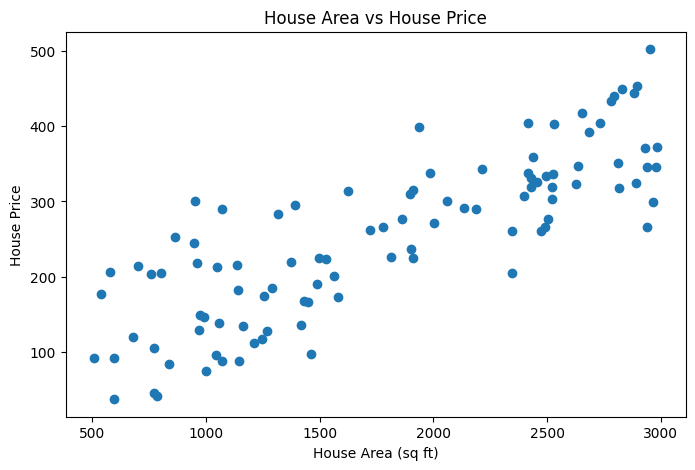

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(area.numpy(), price.numpy())

plt.xlabel("House Area (sq ft)")
plt.ylabel("House Price")
plt.title("House Area vs House Price")

plt.show()

**Price=50+0.12(Area)+20(Bedrooms)−5(Age)+Noise**

In [ ]:
for i in range(5):
    print(
        f"House {i+1}: "
        f"Area={area[i].item():.0f} sq ft, "
        f"Bedrooms={bedrooms[i].item():.0f}, "
        f"Age={age[i].item():.0f} years, "
        f"Price={price[i].item():.2f}"
    )

House 1: Area=2345 sq ft, Bedrooms=1, Age=27 years, Price=205.26
House 2: Area=1164 sq ft, Bedrooms=4, Age=23 years, Price=135.31
House 3: Area=2215 sq ft, Bedrooms=3, Age=10 years, Price=343.23
House 4: Area=1902 sq ft, Bedrooms=1, Age=12 years, Price=236.33
House 5: Area=973 sq ft, Bedrooms=3, Age=17 years, Price=149.84


In [ ]:
torch.manual_seed(42)

# Total number of houses
n = len(X)

# Create random indices
indices = torch.randperm(n)

# 80% training, 20% testing
train_size = int(0.8 * n)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Split X
X_train = X[train_indices]
X_test = X[test_indices]

# Split y
y_train = y[train_indices]
y_test = y[test_indices]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: torch.Size([80, 3])
y_train: torch.Size([80, 1])
X_test : torch.Size([20, 3])
y_test : torch.Size([20, 1])


In [ ]:
X_mean = X_train.mean(dim=0)
X_std = X_train.std(dim=0)

print("Mean:", X_mean)
print("Std :", X_std)

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std


print("Before scaling:")
print(X_train[:5])

print("\nAfter scaling:")
print(X_train_scaled[:5])

Mean: tensor([1811.7125,    2.7750,   14.1000])
Std : tensor([791.8948,   1.4050,   9.4783])
Before scaling:
tensor([[2.5250e+03, 1.0000e+00, 1.4000e+01],
        [1.8960e+03, 4.0000e+00, 9.0000e+00],
        [6.9900e+02, 4.0000e+00, 0.0000e+00],
        [1.9110e+03, 2.0000e+00, 0.0000e+00],
        [9.9000e+02, 1.0000e+00, 8.0000e+00]])

After scaling:
tensor([[ 0.9007, -1.2633, -0.0106],
        [ 0.1064,  0.8719, -0.5381],
        [-1.4051,  0.8719, -1.4876],
        [ 0.1254, -0.5516, -1.4876],
        [-1.0377, -1.2633, -0.6436]])


In [ ]:
import torch.nn as nn

class HousePriceNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(3, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
model = HousePriceNN()

print(model)

HousePriceNN(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [ ]:
sample = X_train_scaled[0].unsqueeze(0)

prediction = model(sample)

print("Input:", sample)
print("Prediction:", prediction)
print("Actual price:", y_train[0])

Input: tensor([[ 0.9007, -1.2633, -0.0106]])
Prediction: tensor([[0.1713]], grad_fn=<AddmmBackward0>)
Actual price: tensor([336.2335])


In [ ]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

epochs = 5000

loss_history = []

for epoch in range(epochs):

    # 1. Forward pass
    predictions = model(X_train_scaled)

    # 2. Calculate loss
    loss = criterion(predictions, y_train)

    # 3. Clear old gradients
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Update weights
    optimizer.step()

    # Store loss
    loss_history.append(loss.item())

    # Print progress
    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [100/5000], Loss: 224.5707
Epoch [200/5000], Loss: 224.5643
Epoch [300/5000], Loss: 224.5404
Epoch [400/5000], Loss: 224.5409
Epoch [500/5000], Loss: 224.5282
Epoch [600/5000], Loss: 224.5531
Epoch [700/5000], Loss: 224.5062
Epoch [800/5000], Loss: 224.5083
Epoch [900/5000], Loss: 224.5212
Epoch [1000/5000], Loss: 224.4712
Epoch [1100/5000], Loss: 224.4526
Epoch [1200/5000], Loss: 224.4152
Epoch [1300/5000], Loss: 224.1591
Epoch [1400/5000], Loss: 224.0872
Epoch [1500/5000], Loss: 224.0181
Epoch [1600/5000], Loss: 224.0083
Epoch [1700/5000], Loss: 223.9426
Epoch [1800/5000], Loss: 223.8897
Epoch [1900/5000], Loss: 223.8521
Epoch [2000/5000], Loss: 223.8539
Epoch [2100/5000], Loss: 223.7882
Epoch [2200/5000], Loss: 223.7626
Epoch [2300/5000], Loss: 223.7445
Epoch [2400/5000], Loss: 223.6927
Epoch [2500/5000], Loss: 223.6980
Epoch [2600/5000], Loss: 223.7575
Epoch [2700/5000], Loss: 223.7553
Epoch [2800/5000], Loss: 223.6432
Epoch [2900/5000], Loss: 223.6287
Epoch [3000/5000], Loss

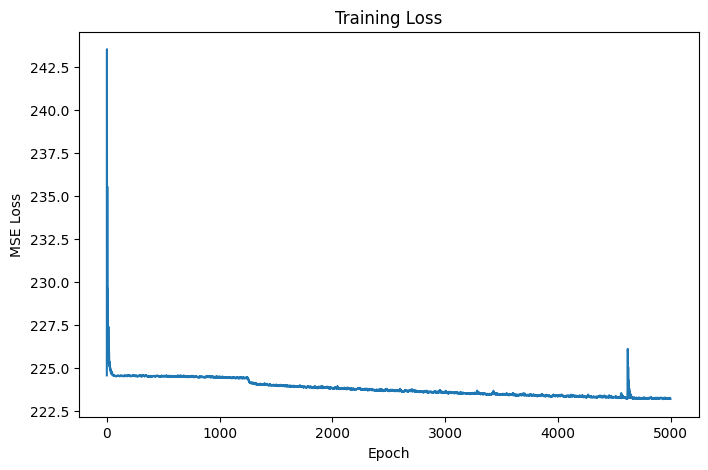

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")

plt.show()

In [ ]:
model.eval()

with torch.no_grad():
    test_predictions = model(X_test_scaled)

print("First 10 predictions:")
print(test_predictions[:10])

print("\nFirst 10 actual prices:")
print(y_test[:10])

First 10 predictions:
tensor([[317.3546],
        [279.0407],
        [313.5397],
        [336.9297],
        [253.4469],
        [247.6793],
        [335.4356],
        [293.0463],
        [262.2780],
        [170.1776]])

First 10 actual prices:
tensor([[343.2256],
        [253.0239],
        [318.7650],
        [345.0646],
        [224.9660],
        [266.4143],
        [324.6403],
        [262.6921],
        [265.7982],
        [166.2062]])


In [ ]:
comparison = torch.cat(
    [y_test, test_predictions],
    dim=1
)

print("Actual Price | Predicted Price")
print(comparison[:10])

Actual Price | Predicted Price
tensor([[343.2256, 317.3546],
        [253.0239, 279.0407],
        [318.7650, 313.5397],
        [345.0646, 336.9297],
        [224.9660, 253.4469],
        [266.4143, 247.6793],
        [324.6403, 335.4356],
        [262.6921, 293.0463],
        [265.7982, 262.2780],
        [166.2062, 170.1776]])


In [ ]:
test_loss = criterion(test_predictions, y_test)

print("Test MSE:", test_loss.item())

Test MSE: 337.7228088378906


In [ ]:
test_rmse = torch.sqrt(test_loss)

print("Test RMSE:", test_rmse.item())

Test RMSE: 18.377235412597656


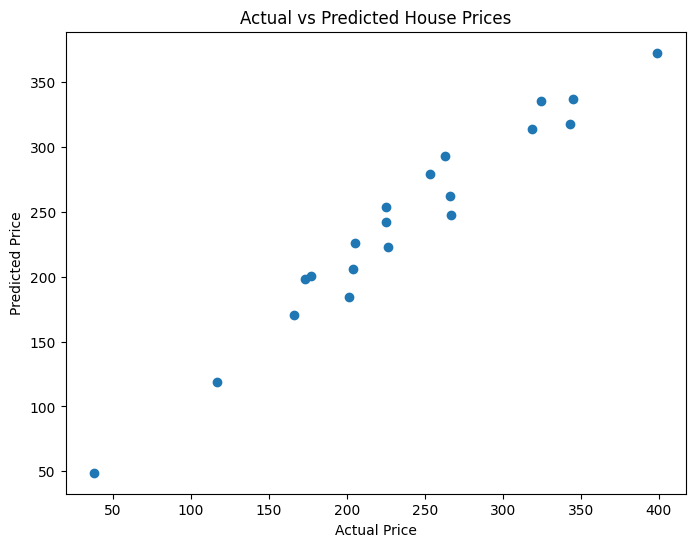

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test.numpy(),
    test_predictions.numpy()
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [ ]:
new_house1 = torch.tensor([
    [2000, 4, 3]
], dtype=torch.float32)

print(new_house1)

tensor([[2000.,    4.,    3.]])


In [ ]:
new_house_scaled1 = (new_house1 - X_mean) / X_std

print(new_house_scaled1)

tensor([[ 0.2378,  0.8719, -1.1711]])


In [ ]:
model.eval()

with torch.no_grad():
    predicted_price = model(new_house_scaled1)

print("Predicted House Price:", predicted_price.item())

Predicted House Price: 353.49261474609375


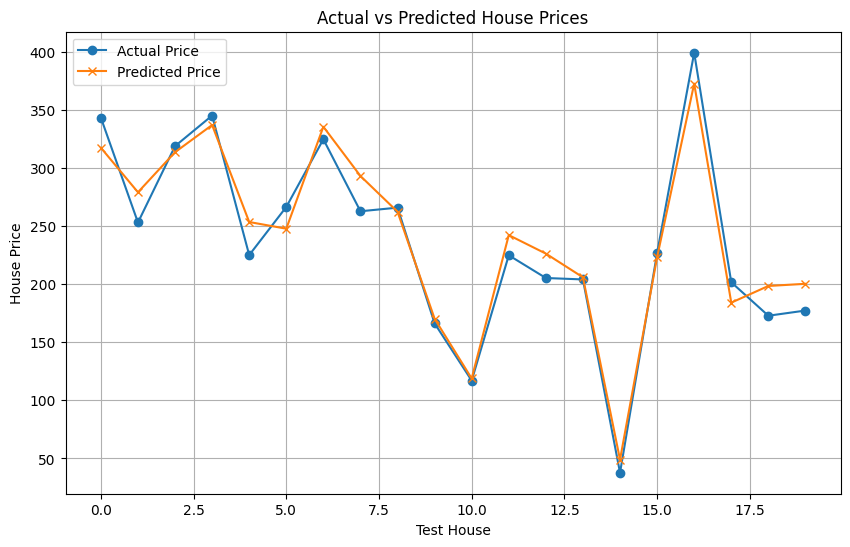

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    y_test.numpy(),
    marker='o',
    label='Actual Price'
)

plt.plot(
    test_predictions.numpy(),
    marker='x',
    label='Predicted Price'
)

plt.xlabel("Test House")
plt.ylabel("House Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)

plt.show()

NOW BINARY CLASSIFICATION


In [ ]:
# Create binary classification target

median_price = price.median()

y_class = (price >= median_price).float()

print("Median house price:", median_price.item())

print("\nFirst 10 prices:")
print(price[:10].squeeze())

print("\nFirst 10 classes:")
print(y_class[:10].squeeze())

Median house price: 262.69207763671875

First 10 prices:
tensor([205.2562, 135.3130, 343.2256, 236.3272, 149.8361, 220.3604,  96.9546,
        325.3091, 318.7650, 338.1455])

First 10 classes:
tensor([0., 0., 1., 0., 0., 0., 0., 1., 1., 1.])


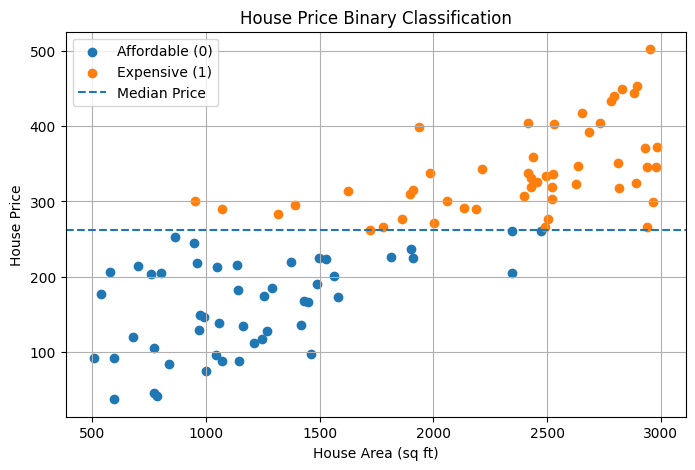

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    area[y_class == 0].numpy(),
    price[y_class == 0].numpy(),
    label="Affordable (0)"
)

plt.scatter(
    area[y_class == 1].numpy(),
    price[y_class == 1].numpy(),
    label="Expensive (1)"
)

plt.axhline(
    median_price.item(),
    linestyle="--",
    label="Median Price"
)

plt.xlabel("House Area (sq ft)")
plt.ylabel("House Price")
plt.title("House Price Binary Classification")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Input features
X = torch.cat(
    [area, bedrooms, age],
    dim=1
)

# Classification target
y = y_class

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX first 5 rows:")
print(X[:5])

print("\ny first 5 values:")
print(y[:5])

X shape: torch.Size([100, 3])
y shape: torch.Size([100, 1])

X first 5 rows:
tensor([[2.3450e+03, 1.0000e+00, 2.7000e+01],
        [1.1640e+03, 4.0000e+00, 2.3000e+01],
        [2.2150e+03, 3.0000e+00, 1.0000e+01],
        [1.9020e+03, 1.0000e+00, 1.2000e+01],
        [9.7300e+02, 3.0000e+00, 1.7000e+01]])

y first 5 values:
tensor([[0.],
        [0.],
        [1.],
        [0.],
        [0.]])


In [ ]:
torch.manual_seed(42)

n = len(X)

# Randomly shuffle the dataset
indices = torch.randperm(n)

# 80% for training
train_size = int(0.8 * n)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Split input features
X_train = X[train_indices]
X_test = X[test_indices]

# Split classification labels
y_train = y[train_indices]
y_test = y[test_indices]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: torch.Size([80, 3])
y_train: torch.Size([80, 1])
X_test : torch.Size([20, 3])
y_test : torch.Size([20, 1])


In [ ]:
# Calculate mean and standard deviation from TRAINING data only

X_mean = X_train.mean(dim=0)
X_std = X_train.std(dim=0)

# Standardize training and testing data
X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

print("Mean:", X_mean)
print("Std :", X_std)

print("\nBefore scaling:")
print(X_train[:5])

print("\nAfter scaling:")
print(X_train_scaled[:5])

Mean: tensor([1811.7125,    2.7750,   14.1000])
Std : tensor([791.8948,   1.4050,   9.4783])

Before scaling:
tensor([[2.5250e+03, 1.0000e+00, 1.4000e+01],
        [1.8960e+03, 4.0000e+00, 9.0000e+00],
        [6.9900e+02, 4.0000e+00, 0.0000e+00],
        [1.9110e+03, 2.0000e+00, 0.0000e+00],
        [9.9000e+02, 1.0000e+00, 8.0000e+00]])

After scaling:
tensor([[ 0.9007, -1.2633, -0.0106],
        [ 0.1064,  0.8719, -0.5381],
        [-1.4051,  0.8719, -1.4876],
        [ 0.1254, -0.5516, -1.4876],
        [-1.0377, -1.2633, -0.6436]])


In [ ]:
import torch.nn as nn

class HouseClassificationNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(3, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
model = HouseClassificationNN()

print(model)

HouseClassificationNN(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)


In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


In [ ]:
epochs = 2000
loss_history = []

for epoch in range(epochs):

    # 1. Forward pass
    logits = model(X_train_scaled)

    # 2. Calculate loss
    loss = criterion(logits, y_train)

    # 3. Clear old gradients
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Update weights
    optimizer.step()

    # Store loss
    loss_history.append(loss.item())

    # Print every 100 epochs
    if (epoch + 1) % 1000 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [1000/2000], Loss: 0.0421
Epoch [2000/2000], Loss: 0.0302


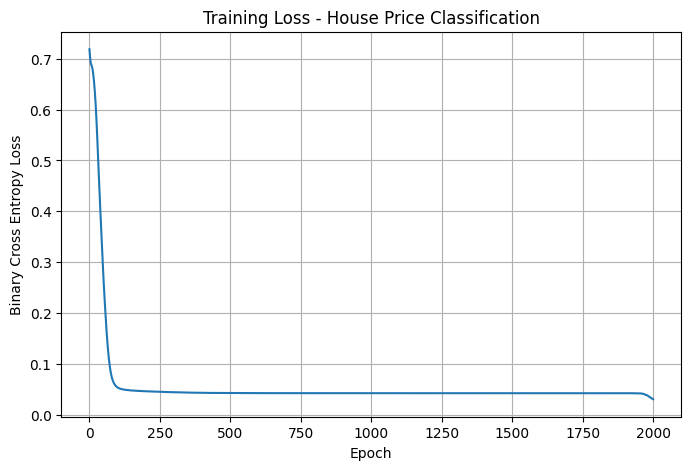

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Training Loss - House Price Classification")
plt.grid(True)

plt.show()

In [ ]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test_scaled)

print("First 10 logits:")
print(test_logits[:10])

First 10 logits:
tensor([[  5.4119],
        [  4.1140],
        [  5.5334],
        [  7.0698],
        [  1.4890],
        [  2.9894],
        [  3.3639],
        [  8.9261],
        [  1.4475],
        [-15.5242]])


In [ ]:
test_probabilities = torch.sigmoid(test_logits)

print("First 10 probabilities:")
print(test_probabilities[:10])

First 10 probabilities:
tensor([[9.9556e-01],
        [9.8392e-01],
        [9.9606e-01],
        [9.9915e-01],
        [8.1593e-01],
        [9.5209e-01],
        [9.6656e-01],
        [9.9987e-01],
        [8.0962e-01],
        [1.8110e-07]])


In [ ]:
test_predictions = (test_probabilities >= 0.5).float()

print("First 10 predicted classes:")
print(test_predictions[:10])

print("\nFirst 10 actual classes:")
print(y_test[:10])

First 10 predicted classes:
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.]])

First 10 actual classes:
tensor([[1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.]])
